# 08 — Hyperparameter tuning and final held-out evaluation
**Objective:** Tune a Random Forest on training folds and compare its cross-validated MAE with the candidate from notebook 06. Select a final model based on training-only evidence, then evaluate **once** on the held-out test set. We use the same split saved in notebook 06.

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, RandomizedSearchCV, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
path = ROOT / "data/processed/cleaned_cars.csv"
df = pd.read_csv(path if path.exists() else ROOT / "data/raw/car_details.csv")
features = ["year", "km_driven", "fuel", "seller_type", "transmission", "owner"]
X, y = df[features], df["selling_price"]
split = joblib.load(ROOT / "models/split_indices.joblib")
X_train, X_test = X.iloc[split["train_idx"]], X.iloc[split["test_idx"]]
y_train, y_test = y.iloc[split["train_idx"]], y.iloc[split["test_idx"]]
groups_train = pd.util.hash_pandas_object(X_train, index=False)
cv = GroupKFold(n_splits=5)

In [2]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), ["year", "km_driven"]),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["fuel", "seller_type", "transmission", "owner"])
])
rf_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("regressor", RandomForestRegressor(random_state=42, n_jobs=-1))
])
search_space = {
    "regressor__n_estimators": [100, 200, 300],
    "regressor__max_depth": [8, 15, 25, None],
    "regressor__min_samples_split": [2, 5, 10],
    "regressor__min_samples_leaf": [1, 2, 4],
    "regressor__max_features": [0.7, 1.0]
}
search = RandomizedSearchCV(
    rf_pipeline, param_distributions=search_space, n_iter=15,
    scoring="neg_mean_absolute_error", cv=cv, random_state=42,
    n_jobs=1, refit=True, verbose=1
)
search.fit(X_train, y_train, groups=groups_train)
print("Tuned RF CV MAE (INR):", round(-search.best_score_))
print("Best parameters:", search.best_params_)

Fitting 5 folds for each of 15 candidates, totalling 75 fits


Tuned RF CV MAE (INR): 193777
Best parameters: {'regressor__n_estimators': 100, 'regressor__min_samples_split': 10, 'regressor__min_samples_leaf': 2, 'regressor__max_features': 0.7, 'regressor__max_depth': 8}


In [3]:
comparison = pd.read_csv(ROOT / "reports/cv_model_comparison.csv")
baseline_name = comparison.iloc[0]["model"]
baseline_cv_mae = float(comparison.iloc[0]["cv_mae_mean"])
tuned_cv_mae = -search.best_score_
print(f"Best original candidate: {baseline_name} | CV MAE ₹{baseline_cv_mae:,.0f}")
print(f"Tuned Random Forest | CV MAE ₹{tuned_cv_mae:,.0f}")
if tuned_cv_mae < baseline_cv_mae:
    final_model = search.best_estimator_
    final_name = "TunedRandomForest"
else:
    final_model = joblib.load(ROOT / "models/baseline_candidate.joblib")
    final_name = baseline_name
print("Selected on CV only:", final_name)

Best original candidate: RandomForest | CV MAE ₹203,644
Tuned Random Forest | CV MAE ₹193,777
Selected on CV only: TunedRandomForest


In [4]:
# FINAL HOLDOUT EVALUATION — do not use these results to reselect the model.
predictions = final_model.predict(X_test)
metrics = {
    "model": final_name,
    "test_rows": int(len(y_test)),
    "test_mae_inr": float(mean_absolute_error(y_test, predictions)),
    "test_rmse_inr": float(np.sqrt(mean_squared_error(y_test, predictions))),
    "test_r2": float(r2_score(y_test, predictions))
}
print(json.dumps(metrics, indent=2))
(ROOT / "reports/final_test_metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")

{
  "model": "TunedRandomForest",
  "test_rows": 892,
  "test_mae_inr": 189566.4557434535,
  "test_rmse_inr": 370314.70220706513,
  "test_r2": 0.5685171131911568
}


163

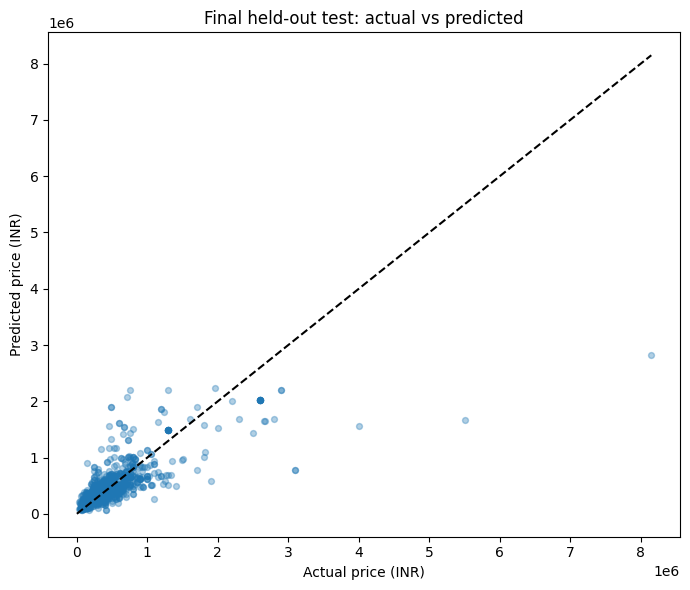

Saved final model to models/best_car_price_model.joblib


In [5]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, predictions, alpha=0.35, s=18)
upper = max(y_test.max(), predictions.max())
ax.plot([0, upper], [0, upper], "k--")
ax.set(xlabel="Actual price (INR)", ylabel="Predicted price (INR)", title="Final held-out test: actual vs predicted")
fig.tight_layout()
fig.savefig(ROOT / "reports/figures/final_test_predictions.png", dpi=150)
plt.show()
joblib.dump(final_model, ROOT / "models/best_car_price_model.joblib")
print("Saved final model to models/best_car_price_model.joblib")

### Final report questions
1. Is test MAE similar to CV MAE? A large gap suggests instability or distribution differences.
2. Does the model beat the Dummy benchmark by a useful margin?
3. Is the typical error acceptable for the business? For a ₹2 lakh car, a ₹1 lakh error would be serious.
4. **Limitations:** The CSV does not include car condition, location, verified sale date, or market inflation. Predictions are historical estimates, not current offers.